# DEPENDENCIES

In [18]:
!pip install opencv-python matplotlib scikit-learn
!pip install torch torchvision
!pip install torch torchvision --index-url https://download.pytorch.org/whl/cu121


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Looking in indexes: https://download.pytorch.org/whl/cu121



[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# IMPORT

In [19]:
import os
import cv2
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torch.optim as optim
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


# PATHS

In [20]:
train_image_dir = "../dataset/DRIVE/training/images"
train_mask_dir = "../dataset/DRIVE/training/1st_manual"

test_image_dir = "../dataset/DRIVE/test/images"
test_mask_dir = "../dataset/DRIVE/test/1st_manual"

# DATASET CLASS

In [21]:
class DriveDataset(Dataset):
    
    def __init__(self, image_dir, mask_dir):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.images = sorted(os.listdir(image_dir))
        
        self.transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Resize((256,256))
        ])
        
    def __len__(self):
        return len(self.images)
    
    def __getitem__(self, idx):

        img_name = self.images[idx]
        img_path = os.path.join(self.image_dir, img_name)

        # Extract image index (e.g., 21 from 21_training.tif)
        number = img_name.split("_")[0]
        mask_name = number + "_manual1.gif"
        mask_path = os.path.join(self.mask_dir, mask_name)

        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        mask = cv2.imread(mask_path, 0)

        if image is None:
            raise ValueError(f"Image not found: {img_path}")
        if mask is None:
            raise ValueError(f"Mask not found: {mask_path}")

        image = self.transform(image)
        mask = self.transform(mask)

        mask = (mask > 0).float()

        return image, mask

# LOAD DATASET

In [22]:
train_dataset = DriveDataset(train_image_dir, train_mask_dir)
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)

print("Training images:", len(train_dataset))

Training images: 20


# VISUALIZE SAMPLE

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000002].


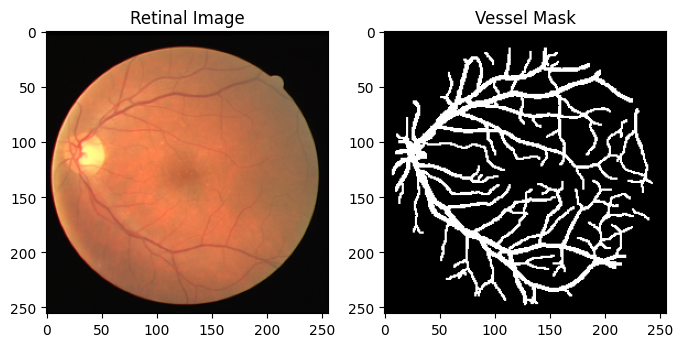

In [23]:
image, mask = train_dataset[0]

plt.figure(figsize=(8,4))

plt.subplot(1,2,1)
plt.title("Retinal Image")
plt.imshow(image.permute(1,2,0))

plt.subplot(1,2,2)
plt.title("Vessel Mask")
plt.imshow(mask.squeeze(), cmap="gray")

plt.show()

# U-NET MODEL

In [24]:
class DoubleConv(nn.Module):
    
    def __init__(self, in_channels, out_channels):
        super().__init__()
        
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels,out_channels,3,padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels,out_channels,3,padding=1),
            nn.ReLU(inplace=True)
        )
        
    def forward(self,x):
        return self.conv(x)


class UNet(nn.Module):
    
    def __init__(self):
        super().__init__()
        
        self.down1 = DoubleConv(3,64)
        self.down2 = DoubleConv(64,128)
        self.down3 = DoubleConv(128,256)
        
        self.pool = nn.MaxPool2d(2)
        
        self.middle = DoubleConv(256,512)
        
        self.up3 = nn.ConvTranspose2d(512,256,2,stride=2)
        self.conv3 = DoubleConv(512,256)
        
        self.up2 = nn.ConvTranspose2d(256,128,2,stride=2)
        self.conv2 = DoubleConv(256,128)
        
        self.up1 = nn.ConvTranspose2d(128,64,2,stride=2)
        self.conv1 = DoubleConv(128,64)
        
        self.out = nn.Conv2d(64,1,1)
        
    def forward(self,x):
        
        d1 = self.down1(x)
        p1 = self.pool(d1)
        
        d2 = self.down2(p1)
        p2 = self.pool(d2)
        
        d3 = self.down3(p2)
        p3 = self.pool(d3)
        
        m = self.middle(p3)
        
        u3 = self.up3(m)
        u3 = torch.cat([u3,d3],dim=1)
        u3 = self.conv3(u3)
        
        u2 = self.up2(u3)
        u2 = torch.cat([u2,d2],dim=1)
        u2 = self.conv2(u2)
        
        u1 = self.up1(u2)
        u1 = torch.cat([u1,d1],dim=1)
        u1 = self.conv1(u1)
        
        return torch.sigmoid(self.out(u1))

# INITIALIZE MODEL

In [25]:
model = UNet().to(device)

optimizer = optim.Adam(model.parameters(), lr=1e-4)
loss_fn = nn.BCELoss()

print(model)

UNet(
  (down1): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (down2): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (down3): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (middle): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(256, 512, kernel_size=(3

# DICE SCORE METRIC

In [26]:
def dice_score(pred, target):
    
    smooth = 1e-6
    
    pred = pred.view(-1)
    target = target.view(-1)
    
    intersection = (pred * target).sum()
    
    return (2*intersection + smooth) / (pred.sum() + target.sum() + smooth)

# TRAINING LOOP

In [27]:
epochs = 100

for epoch in range(epochs):
    
    model.train()
    epoch_loss = 0
    
    for images, masks in train_loader:
        
        images = images.to(device)
        masks = masks.to(device)
        
        preds = model(images)
        
        loss = loss_fn(preds, masks)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
        
    print(f"Epoch {epoch+1}/{epochs}  Loss: {epoch_loss/len(train_loader):.4f}")

Epoch 1/100  Loss: 0.6852
Epoch 2/100  Loss: 0.6718
Epoch 3/100  Loss: 0.6524
Epoch 4/100  Loss: 0.6139
Epoch 5/100  Loss: 0.5799
Epoch 6/100  Loss: 0.5669
Epoch 7/100  Loss: 0.5556
Epoch 8/100  Loss: 0.5323
Epoch 9/100  Loss: 0.4937
Epoch 10/100  Loss: 0.4505
Epoch 11/100  Loss: 0.4302
Epoch 12/100  Loss: 0.4267
Epoch 13/100  Loss: 0.4255
Epoch 14/100  Loss: 0.4232
Epoch 15/100  Loss: 0.4211
Epoch 16/100  Loss: 0.4205
Epoch 17/100  Loss: 0.4194
Epoch 18/100  Loss: 0.4182
Epoch 19/100  Loss: 0.4176
Epoch 20/100  Loss: 0.4170
Epoch 21/100  Loss: 0.4166
Epoch 22/100  Loss: 0.4157
Epoch 23/100  Loss: 0.4151
Epoch 24/100  Loss: 0.4145
Epoch 25/100  Loss: 0.4148
Epoch 26/100  Loss: 0.4145
Epoch 27/100  Loss: 0.4140
Epoch 28/100  Loss: 0.4141
Epoch 29/100  Loss: 0.4135
Epoch 30/100  Loss: 0.4133
Epoch 31/100  Loss: 0.4132
Epoch 32/100  Loss: 0.4129
Epoch 33/100  Loss: 0.4132
Epoch 34/100  Loss: 0.4132
Epoch 35/100  Loss: 0.4128
Epoch 36/100  Loss: 0.4126
Epoch 37/100  Loss: 0.4129
Epoch 38/1

# PREDICTION

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000002].


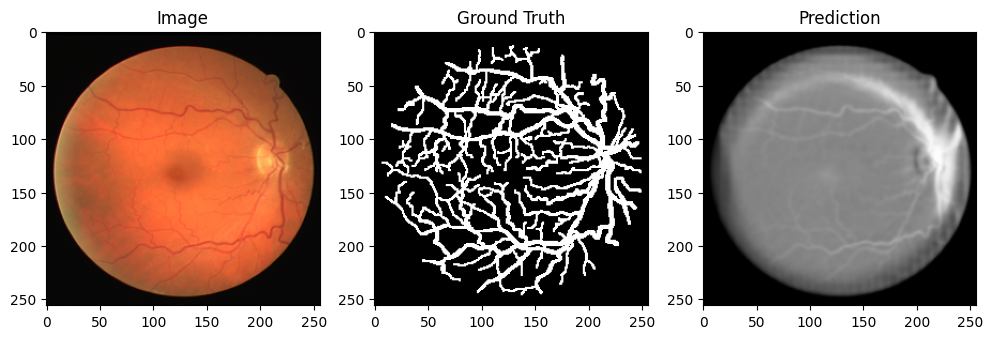

In [28]:
model.eval()

image, mask = train_dataset[1]

with torch.no_grad():
    
    pred = model(image.unsqueeze(0).to(device))
    pred = pred.squeeze().cpu().numpy()

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.title("Image")
plt.imshow(image.permute(1,2,0))

plt.subplot(1,3,2)
plt.title("Ground Truth")
plt.imshow(mask.squeeze(), cmap="gray")

plt.subplot(1,3,3)
plt.title("Prediction")
plt.imshow(pred, cmap="gray")

plt.show()

# SAVE MODEL

In [29]:
torch.save(model.state_dict(), "unet_drive.pth")